# [GSE149510](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE149510)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2021-02-22
> - Modified: 2025-07-19

# 1. Experimental Design

> 	ALKBH5 impacts malignancy of hepatocellular carcinoma via m6A-mediated epigenetic modulation.
> - Chen, Y., Zhao, Y., Chen, J. et al. ALKBH5 suppresses malignancy of hepatocellular carcinoma via m6A-guided epigenetic inhibition of LYPD1. Mol Cancer 19, 123 (2020). https://doi.org/10.1186/s12943-020-01239-w.
> - MeRIP-seq
> - Illumina NovaSeq, PE150
> - hg38

| Sample | Organism | Cell | Source | Treatment | Antibody | Replicate |
| - | - | - | - | - | - | - |
| ALKBH5-NC | Homo sapiens | HCCLM3 | Hepatocellular carcinoma cell | Vector-transfected | m6A | rep1~2 |
| ALKBH5-OE | Homo sapiens | HCCLM3 | Hepatocellular carcinoma cell | Overexpression | m6A | rep1~2 |

In [1]:
library(tidyverse)
suppressPackageStartupMessages({
    library(rtracklayer)
    library(GenomicRanges)
    library(GenomeInfoDb)
    library(RColorBrewer)
    library(viridis)
    library(cowplot)
})

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
data_dir <- "~/dataset_1/bulk_omics/meripseq_Hs_HCCLM3_ALKBH5_GSE149510/02_output"

gtf_file <- "~/reference/Homo_sapiens/hg38/gencode.v48.annotation.gtf"

suppressPackageStartupMessages(library(BSgenome.Hsapiens.UCSC.hg38))
genome <- BSgenome.Hsapiens.UCSC.hg38

In [ ]:
# load reference gene anntotion
gtf <- import(gtf_file) |>
    BRGenomics::tidyChromosomes(keep.X = TRUE, keep.Y = TRUE, keep.M = FALSE)

txdb <- txdbmaker::makeTxDbFromGRanges(
    gtf, drop.stop.codons = TRUE, taxonomyId = 9606, 
    metadata = data.frame(
        name = c("Genome", "Gencode Release"), 
        value = c("hg38", "v48")))

Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
“The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored.”
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
“genome version information is not available for this TxDb object”


# 2. Data Import

## 1). narrowPeak Import

In [4]:
source("~/biology_knowledge_base/06_analysis/00_script/r/01_data_import/load_peaks.R")

In [ ]:
peaks_files1 <- file.path(data_dir, "05_peaks") |>
    list.files(pattern = "_m6A_peaks\\.narrowPeak$", full.names = TRUE) |>
    set_names(~ sub("(.*)_m6A_peaks\\.narrowPeak$", "\\1_macs2", basename(.x)))

peaks_files2 <- file.path(data_dir, "05_exomePeak2") |>
    list.files(pattern = "peaks\\.bed$", recursive = TRUE, full.names = TRUE) |>
    set_names(~ sub("_m6A$", "_exomePeak2", basename(dirname(.x))))

peaks_files <- c(peaks_files1, peaks_files2)

paste(names(peaks_files), basename(peaks_files), sep = ": ") |>
    cat(sep = "\n")

HCCLM3_ALKBH5_NC_rep1_macs2: HCCLM3_ALKBH5_NC_rep1_m6A_peaks.narrowPeak
HCCLM3_ALKBH5_NC_rep2_macs2: HCCLM3_ALKBH5_NC_rep2_m6A_peaks.narrowPeak
HCCLM3_ALKBH5_OE_rep1_macs2: HCCLM3_ALKBH5_OE_rep1_m6A_peaks.narrowPeak
HCCLM3_ALKBH5_OE_rep2_macs2: HCCLM3_ALKBH5_OE_rep2_m6A_peaks.narrowPeak
HCCLM3_ALKBH5_NC_rep1_exomePeak2: peaks.bed
HCCLM3_ALKBH5_NC_rep2_exomePeak2: peaks.bed
HCCLM3_ALKBH5_OE_rep1_exomePeak2: peaks.bed
HCCLM3_ALKBH5_OE_rep2_exomePeak2: peaks.bed


In [6]:
peaks_list <- lapply(peaks_files, load_peaks, dropSex = FALSE, verbose = FALSE)

In [7]:
peaks_list[1]

$HCCLM3_ALKBH5_NC_rep1_macs2
GRanges object with 14009 ranges and 6 metadata columns:
          seqnames            ranges strand |                   name     score
             <Rle>         <IRanges>  <Rle> |            <character> <numeric>
      [1]     chr1       14475-14788      * | HCCLM3_ALKBH5_NC_rep..        33
      [2]     chr1   1055049-1055889      * | HCCLM3_ALKBH5_NC_rep..      1008
      [3]     chr1   1065835-1066147      * | HCCLM3_ALKBH5_NC_rep..       129
      [4]     chr1   1082217-1083021      * | HCCLM3_ALKBH5_NC_rep..       164
      [5]     chr1   1217396-1217794      * | HCCLM3_ALKBH5_NC_rep..        20
      ...      ...               ...    ... .                    ...       ...
  [14005]     chrY 12917965-12918298      * | HCCLM3_ALKBH5_NC_rep..       232
  [14006]     chrY 19587172-19587368      * | HCCLM3_ALKBH5_NC_rep..       112
  [14007]     chrY 19590050-19590239      * | HCCLM3_ALKBH5_NC_rep..       353
  [14008]     chrY 19603771-19604013      * |

In [8]:
peaks_list[5]

$HCCLM3_ALKBH5_NC_rep1_exomePeak2
GRanges object with 41059 ranges and 5 metadata columns:
          seqnames              ranges strand |        name     score
             <Rle>           <IRanges>  <Rle> | <character> <numeric>
      [1]    chr20   50958965-50959139      - |           1   5.95788
      [2]    chr20   50958865-50958939      - |           2   5.21650
      [3]    chr20   50957146-50958529      - |           3   8.49130
      [4]    chr20   50955171-50955295      - |           4   9.07629
      [5]    chr20   50945824-50948678      - |           5  13.24078
      ...      ...                 ...    ... .         ...       ...
  [41055]     chr8 119855613-119855737      + |       41117   6.50675
  [41056]     chr8 119868797-119868971      + |       41118   6.16478
  [41057]     chr9 136992972-136992996      + |       41119   6.93194
  [41058]     chr9 136993047-136993420      + |       41120  11.41743
  [41059]     chr9 136993571-136993971      + |       41121  33.23703

In [9]:
coldata <- data.frame(sample = names(peaks_list)) |>
    mutate(
        .parts = str_split(sample, "_"), 
        Cell = map_chr(.parts, ~ .x[1]), 
        Genotype = map_chr(.parts, ~ paste(.x[2], .x[3], sep = "-")) |>
            factor(levels = c("ALKBH5-NC", "ALKBH5-OE")), 
        Replicate = map_chr(.parts, ~ .x[4]) |> factor(),
        Method = map_chr(.parts, ~ .x[5]) |> 
            factor(levels = c("macs2", "exomePeak2"))
    ) |>
    dplyr::select(-.parts) |>
    column_to_rownames("sample")

coldata

,Cell,Genotype,Replicate,Method
,<chr>,<fct>,<fct>,<fct>
HCCLM3_ALKBH5_NC_rep1_macs2,HCCLM3,ALKBH5-NC,rep1,macs2
HCCLM3_ALKBH5_NC_rep2_macs2,HCCLM3,ALKBH5-NC,rep2,macs2
HCCLM3_ALKBH5_OE_rep1_macs2,HCCLM3,ALKBH5-OE,rep1,macs2
HCCLM3_ALKBH5_OE_rep2_macs2,HCCLM3,ALKBH5-OE,rep2,macs2
HCCLM3_ALKBH5_NC_rep1_exomePeak2,HCCLM3,ALKBH5-NC,rep1,exomePeak2
HCCLM3_ALKBH5_NC_rep2_exomePeak2,HCCLM3,ALKBH5-NC,rep2,exomePeak2
HCCLM3_ALKBH5_OE_rep1_exomePeak2,HCCLM3,ALKBH5-OE,rep1,exomePeak2
HCCLM3_ALKBH5_OE_rep2_exomePeak2,HCCLM3,ALKBH5-OE,rep2,exomePeak2


# 3. Quality Control

## 1). Mapping Statistics

| Sample | Total Fragments | Mapping Fragments | Mapping Rate | Unique Mapping Fragments | Unique Mapping Rate | PCR Duplicates Rate | Number Of Peaks |
| - | - | - | - | - | - | - | - |
| - | - | - | - | - | - | - | - |

## 2). Number of Peaks

In [ ]:
plot_df <- data.frame(
    sample = names(peaks_list), 
    number = lengths(peaks_list), 
    number_plus = map_int(peaks_list, ~ sum(strand(.x) == "+")), 
    number_minus = map_int(peaks_list, ~ sum(strand(.x) == "-"))
) |>
    left_join(
        coldata |> rownames_to_column("sample"), by = "sample"
) |>
    column_to_rownames("sample")

head(plot_df)

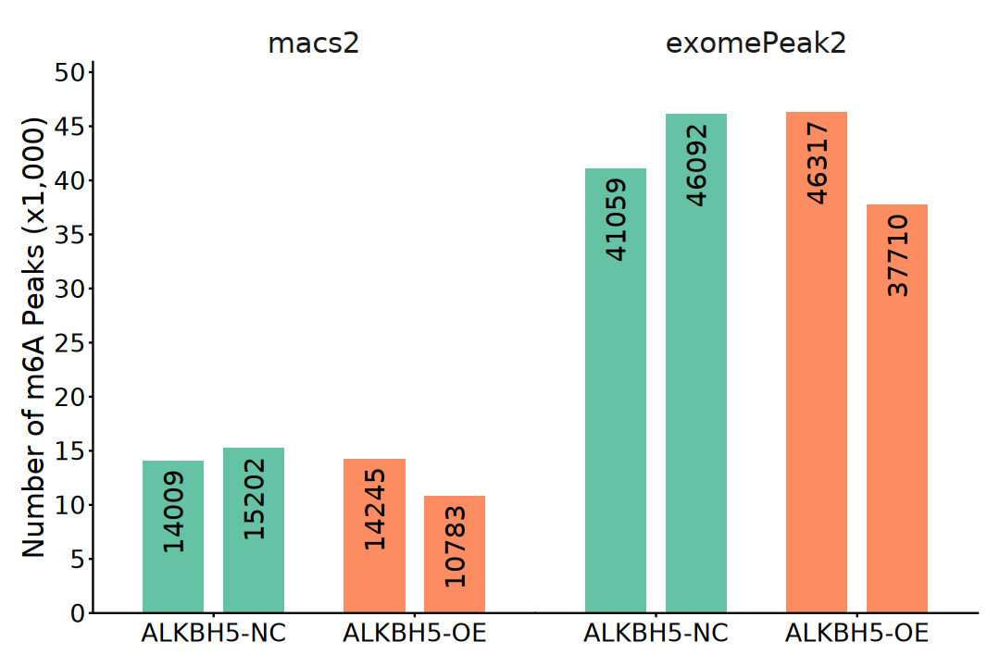

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(Genotype, number, group = Replicate)) +
    geom_bar(
        aes(fill = Genotype), stat = "identity", width = 0.6, 
        position = position_dodge(width = 0.8)) +
    geom_text(
        aes(label = number), angle = 90, hjust = 1.1, vjust = 0.5, size = 6, 
        position = position_dodge(width = 0.8)) +
    facet_wrap(~ Method) +
    scale_y_continuous(
        breaks = seq(0, 50000, 5000), labels = seq(0, 50, 5), 
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Number of m6A Peaks (x1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        panel.spacing.x = unit(0, "lines"), 
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.position = "none", 
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 0, vjust = 0.5), 
        axis.text.y = element_text(size = 16))

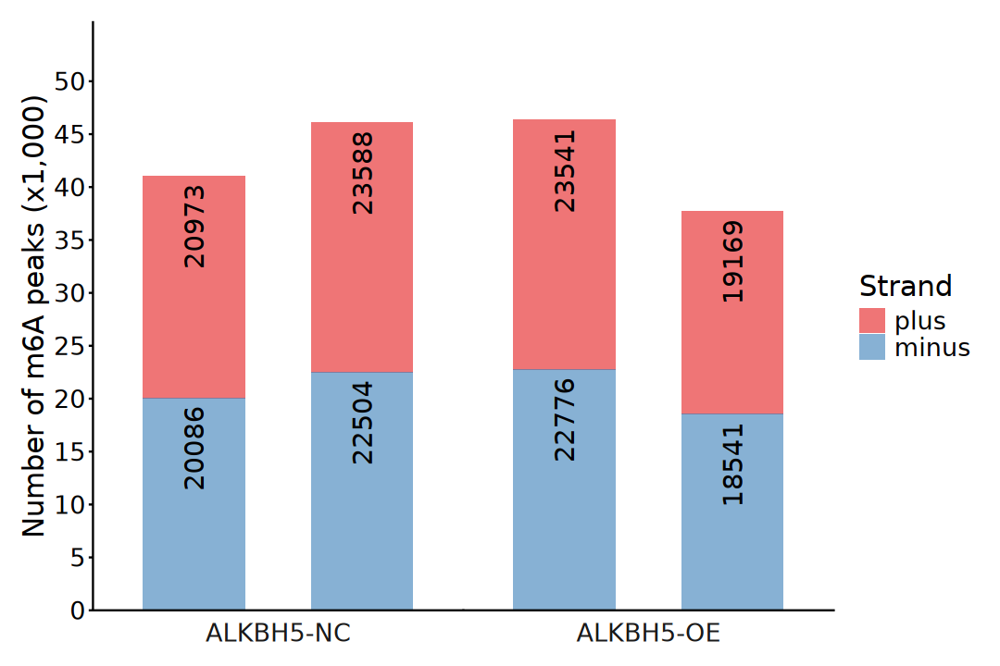

In [12]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot_df |>
    pivot_longer(
        cols = c(number_plus, number_minus), names_to = "Strand", 
        names_prefix = "number_", values_to = "Count"
    ) |>
    mutate(Strand = factor(Strand, levels = c("plus", "minus"))) |>
    filter(Count > 0) |>
ggplot(aes(x = Replicate, y = Count, fill = Strand)) +
    geom_bar(
        stat = "identity", alpha = 0.6, width = 0.6, 
        position = position_stack()) +
    geom_text(
        aes(label = Count), angle = 90, hjust = 1.1, vjust = 0.5, size = 6, 
        position = position_stack()) +
    facet_wrap(~ Genotype, nrow = 1, strip.position = "bottom") +
    scale_y_continuous(
        breaks = seq(0, 50000, 5000), labels = seq(0, 50, 5), 
        expand = expansion(mult = c(0, 0.2))) +
    scale_fill_brewer(palette = "Set1") +
    labs(x = NULL, y = "Number of m6A peaks (x1,000)") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing.x = unit(0, "lines"), 
        strip.placement = "outside", 
        strip.background = element_blank(), 
        strip.text.x = element_text(size = 16, margin = margin(t = 4)),
        legend.position = "right",
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_blank(), 
        axis.text.y = element_text(size = 16),
        axis.ticks.x = element_blank())

## 3). Replicate Consistency

In [13]:
# ------------------------------------------------------------------------------
# Function: summarize_peak_overlaps
#
# Description:
# Summarize the overlap composition of peak sets across replicates.
#
# Arguments:
#   peaks_list : named list of GRanges.
#   peaks      : short names used for display and ordering.
#                Default: rep1, rep2, ..., repN.
# ------------------------------------------------------------------------------
summarize_peak_overlaps <- function(
    peaks_list, peaks = paste0("rep", seq_along(peaks_list)), 
    ignore.strand = TRUE) {

    names(peaks_list) <- peaks

    comb_levels <- unlist(
        lapply(seq_along(peaks), function(i) {
            combn(peaks, i, FUN = paste, collapse = "&")
        }), use.names = FALSE)

    ol <- lapply(peaks_list, function(gr) {
            names(gr) <- gr$name
            return(gr)
        }) |>
            ChIPpeakAnno::findOverlapsOfPeaks(
                ignore.strand = ignore.strand)

    ol$venn_cnt[, c(names(peaks_list), "Counts"), drop = FALSE] |>
        as.data.frame(stringsAsFactors = FALSE) |>
        dplyr::rename_with(~ peaks, .cols = names(peaks_list)) |>
        dplyr::rowwise() |>
        dplyr::mutate(
            Combination = {
                present <- peaks[c_across(dplyr::all_of(peaks)) == 1]
                if (length(present) == 0) {
                    NA_character_
                } else {
                    paste(present, collapse = "&")
                }
            }
        ) |>
        dplyr::ungroup() |>
        dplyr::mutate(
            Combination = factor(Combination, levels = comb_levels)) |>
        dplyr::filter(!is.na(Combination)) |>
        dplyr::select(Combination, Counts) |>
        as.data.frame()
}

In [14]:
overlap_summary <- coldata |>
    split(~ Genotype + Method, drop = TRUE) |>
    purrr::imap_dfr(function(df, group_name) {
        method <- unique(df$Method)
        group  <- unique(df$Genotype)
        summarize_peak_overlaps(
            peaks_list[rownames(df)], ignore.strand = method == "macs2") |>
            mutate(Method = method, Group = group, .before = 1)
    })

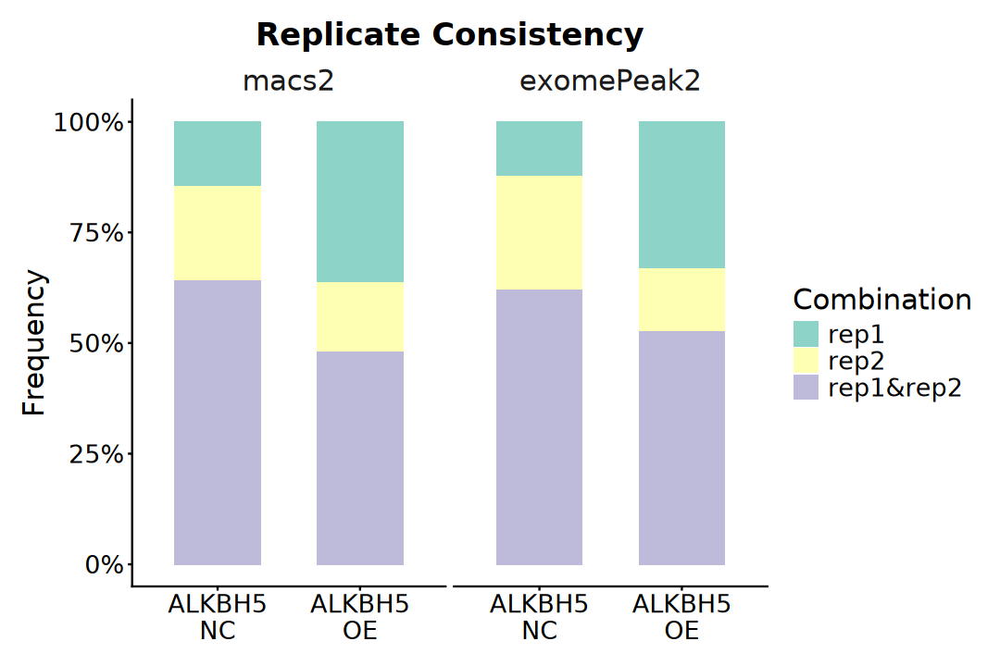

In [15]:
options(repr.plot.width = 9, repr.plot.height = 6)

overlap_summary |>
    mutate(Group = str_replace_all(Group, "-", "\n")) |>
ggplot(aes(x = Group, y = Counts, fill = Combination)) +
    geom_bar(stat = "identity", position = "fill", width = 0.6) +
    scale_y_continuous(labels = scales::percent_format()) +
    scale_fill_brewer(palette = "Set3") +
    facet_wrap(~ Method, nrow = 1) +
    labs(title = "Replicate Consistency", x = NULL, y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        strip.background = element_blank(), 
        strip.text = element_text(size = 18), 
        legend.position = "right", 
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 4). Peak Annotation

In [16]:
suppressPackageStartupMessages(library(ChIPseeker))

In [17]:
# Annotate m6A peaks at transcript level
peaks_anno_list <- lapply(
    peaks_list, 
    annotatePeak, 
    TxDb = txdb, 
    tssRegion = c(0, 0), 
    level = "transcript", 
    sameStrand = TRUE, 
    genomicAnnotationPriority = c(
        "5UTR", "3UTR", "Exon", "Intron", 
        "Promoter", "Downstream", "Intergenic"), 
    verbose = FALSE
)

>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...
>> Using Genome: hg38 ...


Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the ChIPseeker package.
  Please report the issue at <https://github.com/YuLab-SMU/ChIPseeker/issues>."


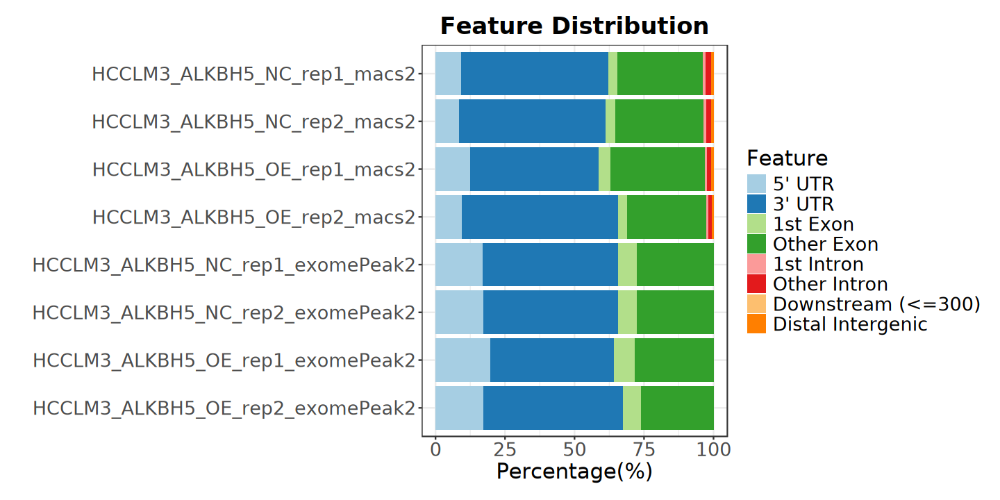

In [18]:
options(repr.plot.width = 12, repr.plot.height = 6)

plotAnnoBar(peaks_anno_list) +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.position = "right", 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [19]:
# Simplify transcript-region annotation
format_peak_annotation <- function(anno) {
    anno@anno |>
        as.data.frame() |>
        mutate(
            Category = case_when(
                grepl("5' UTR", annotation, fixed = TRUE) ~ "5' UTR",
                grepl("3' UTR", annotation, fixed = TRUE) ~ "3' UTR",
                grepl("Exon", annotation, fixed = TRUE) ~ "CDS",
                grepl("Intron", annotation, fixed = TRUE) ~ "Intron",
                TRUE ~ "Intergenic"
            )
        ) |>
        as("GRanges")
}

In [20]:
peaks_anno_list <- lapply(peaks_anno_list, format_peak_annotation)

In [21]:
# Prepare transcript biotype information
tx_info <- data.frame(
    transcript_id = as.character(gtf$transcript_id),
    gene_type = as.character(gtf$gene_type)
) |>
    filter(
        !is.na(transcript_id), transcript_id != "", 
        !is.na(gene_type), gene_type != "") |>
    distinct(transcript_id, .keep_all = TRUE)

In [22]:
# Collapse detailed GENCODE gene types into broader categories
collapse_gene_type <- function(x) {
    x <- as.character(x)
    case_when(
        is.na(x) | x == "" ~ NA_character_,
        grepl("pseudogene", x) ~ "pseudogene",
        x == "protein_coding" | 
            grepl("^(IG|TR)_.+_gene$", x) ~ "protein_coding",
        x == "lncRNA" ~ "lncRNA",
        x %in% c(
            "miRNA", "snRNA", "snoRNA", "scaRNA", "sRNA", "scRNA",
            "vault_RNA", "vaultRNA", "tRNA", "Mt_tRNA") ~ "small_RNA",
        x %in% c("rRNA", "Mt_rRNA") ~ "rRNA",
        TRUE ~ "other"
    )
}

In [23]:
# Add gene type to annotated peaks
add_gene_type <- function(gr) {
    idx <- match(gr$transcriptId, tx_info$transcript_id)
    gr$gene_type <- collapse_gene_type(tx_info$gene_type[idx])
    gr
}

In [24]:
peaks_anno_list <- lapply(peaks_anno_list, add_gene_type)

In [25]:
plot_df <- map_dfr(peaks_anno_list, ~ as.data.frame(.x), .id = "sample") |>
    mutate(gene_type = replace_na(gene_type, "unannotated")) |>
    count(sample, gene_type, name = "n") |>
    group_by(sample) |>
    mutate(percent = n / sum(n) * 100) |>
    ungroup() |>
    mutate(gene_type = factor(gene_type, levels = c(
        "protein_coding", "lncRNA", "small_RNA", "rRNA",
        "pseudogene", "other", "unannotated"))) |>
    mutate(sample = sub("HCCLM3_ALKBH5_", "", sample))

head(plot_df)

sample,gene_type,n,percent
<chr>,<fct>,<int>,<dbl>
NC_rep1_exomePeak2,lncRNA,5398,13.14693490
NC_rep1_exomePeak2,other,446,1.08624175
NC_rep1_exomePeak2,protein_coding,33403,81.35366180
NC_rep1_exomePeak2,pseudogene,978,2.38193819
NC_rep1_exomePeak2,rRNA,1,0.00243552
NC_rep1_exomePeak2,small_RNA,833,2.02878784


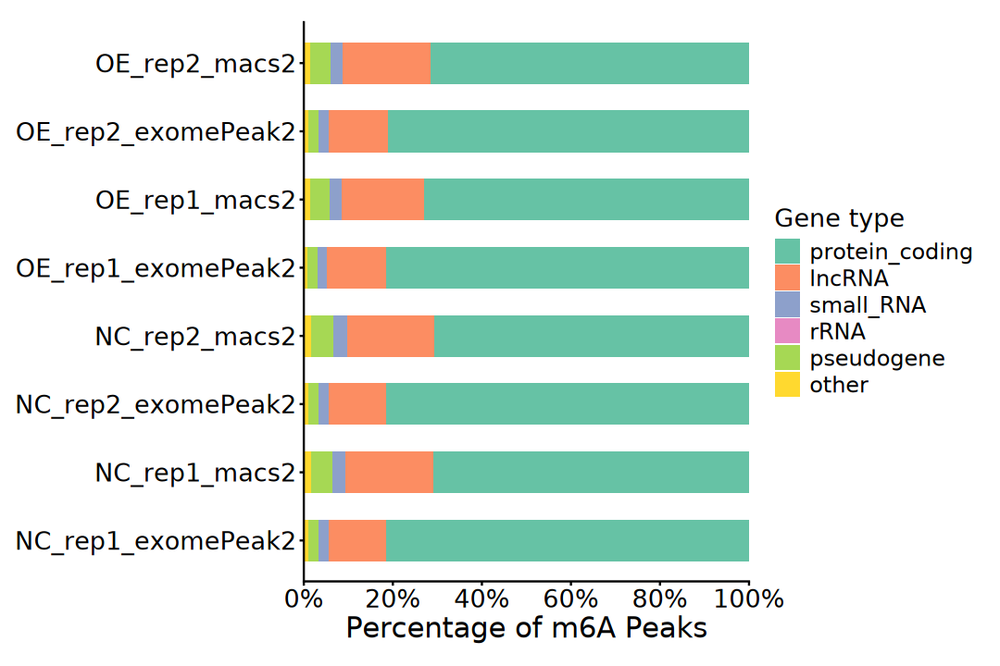

In [26]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(sample, percent, fill = gene_type)) +
    geom_bar(stat = "identity", width = 0.6) +
    scale_y_continuous(
        breaks = seq(0, 100, 20), labels = paste0(seq(0, 100, 20), "%"),
        expand = expansion(mult = c(0, 0))) +
    scale_fill_brewer(palette = "Set2") +
    coord_flip() +
    labs(x = NULL, y = "Percentage of m6A Peaks", fill = "Gene type") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 16),
        legend.text = element_text(size = 14),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

## 5). Guitar Plot

In [27]:
suppressPackageStartupMessages(library(Guitar))

In [28]:
guitarTxdb <- makeGuitarTxdb(
    txdb, txpromoterLength = 0, txtailLength = 0,
    pltTxType =  "mrna", withTxContext = TRUE)

[1] "There are 385632 transcripts of 78649 genes in the genome."
[1] "total 385632 transcripts extracted ..."
[1] "total 126108 transcripts left after ambiguity filter ..."
[1] "total 126108 transcripts left after check chromosome validity ..."
[1] "total 10856 mRNAs left after component length filter ..."
[1] "total 91007 ncRNAs left after ncRNA length filter ..."
[1] "generate components for mRNA"
[1] "generate chiped transcriptome"
[1] "generate coverage checking ranges for mrna"


In [29]:
str(guitarTxdb$mrna$componentWidthAverage_pct)

 Named num [1:5] 0 0.132 0.434 0.434 0
 - attr(*, "names")= chr [1:5] "promoter" "utr5" "cds" "utr3" ...


In [30]:
txMrnaComponentProp <- guitarTxdb$mrna$componentWidthAverage_pct

In [31]:
# ~5 min
plot_guitar_dat <- GuitarPlot(
    txTxdb = txdb, 
    stGRangeLists = peaks_list, 
    headOrtail = FALSE, 
    enableCI = FALSE, 
    mapFilterTranscript = TRUE, 
    pltTxType = "mrna", 
    stGroupName = names(peaks_list)
)

[1] "20260920154626"
[1] "There are 385632 transcripts of 78649 genes in the genome."
[1] "total 385632 transcripts extracted ..."
[1] "total 126108 transcripts left after ambiguity filter ..."
[1] "total 126108 transcripts left after check chromosome validity ..."
[1] "total 10856 mRNAs left after component length filter ..."
[1] "total 91007 ncRNAs left after ncRNA length filter ..."
[1] "generate components for mRNA"
[1] "generate chiped transcriptome"
[1] "generate coverage checking ranges for mrna"
[1] "20260920155038"
[1] "sample 10 points for HCCLM3_ALKBH5_NC_rep1_macs2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 8 out-of-bound ranges located on sequences
  ENST00000376217.6, ENST00000498824.5, ENST00000601610.5, ENST00000296503.10,
  ENST00000524898.2, ENST00000357039.9, ENST00000374594.1, and
  ENST00000457894.5. Note that ranges located on a sequence whose length is
  unknown (NA) or on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags of the
  underlying sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information."


[1] "sample 10 points for HCCLM3_ALKBH5_NC_rep2_macs2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 6 out-of-bound ranges located on sequences
  ENST00000367925.6, ENST00000296503.10, ENST00000524898.2, ENST00000357039.9,
  ENST00000374594.1, and ENST00000457894.5. Note that ranges located on a
  sequence whose length is unknown (NA) or on a circular sequence are not
  considered out-of-bound (use seqlengths() and isCircular() to get the lengths
  and circularity flags of the underlying sequences). You can use trim() to
  trim these ranges. See ?`trim,GenomicRanges-method` for more information."


[1] "sample 10 points for HCCLM3_ALKBH5_OE_rep1_macs2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 8 out-of-bound ranges located on sequences
  ENST00000368222.8, ENST00000367925.6, ENST00000237500.10, ENST00000342166.10,
  ENST00000296503.10, ENST00000357039.9, ENST00000374594.1, and
  ENST00000457894.5. Note that ranges located on a sequence whose length is
  unknown (NA) or on a circular sequence are not considered out-of-bound (use
  seqlengths() and isCircular() to get the lengths and circularity flags of the
  underlying sequences). You can use trim() to trim these ranges. See
  ?`trim,GenomicRanges-method` for more information."


... (8 outputs left out)

[1] "sample 10 points for HCCLM3_ALKBH5_OE_rep2_exomePeak2"


Warning message in valid.GenomicRanges.seqinfo(x, suggest.trim = TRUE):
"GRanges object contains 230 out-of-bound ranges located on sequences
  ENST00000005257.7, ENST00000597436.5, ENST00000452973.6, ENST00000019317.8,
  ENST00000367440.3, ENST00000261507.11, ENST00000539888.5, ENST00000371224.7,
  ENST00000085079.11, ENST00000532692.1, ENST00000369755.4, ENST00000429642.2,
  ENST00000232496.5, ENST00000178638.8, ENST00000377045.9, ENST00000367941.7,
  ENST00000380420.10, ENST00000378883.5, ENST00000455836.1, ENST00000321265.10,
  ENST00000541285.1, ENST00000337147.11, ENST00000366930.9, ENST00000392859.7,
  ENST00000215730.12, ENST00000216068.9, ENST00000329563.8, ENST00000416967.1,
  ENST00000715725.2, ENST00000397152.7, ENST00000374837.7, ENST00000415430.7,
  ENST00000376327.6, ENST00000404933.7, ENST00000523430.5, ENST00000263382.8,
  ENST00000222803.10, ENST00000262570.10, ENST00000402924.5, ENST00000373970.4,
  ENST00000225171.7, ENST00000393408.7, ENST00000575197.1, ENST0000026

[1] "start figure plotting for mrna ..."


Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the Guitar package.
  Please report the issue to the authors."


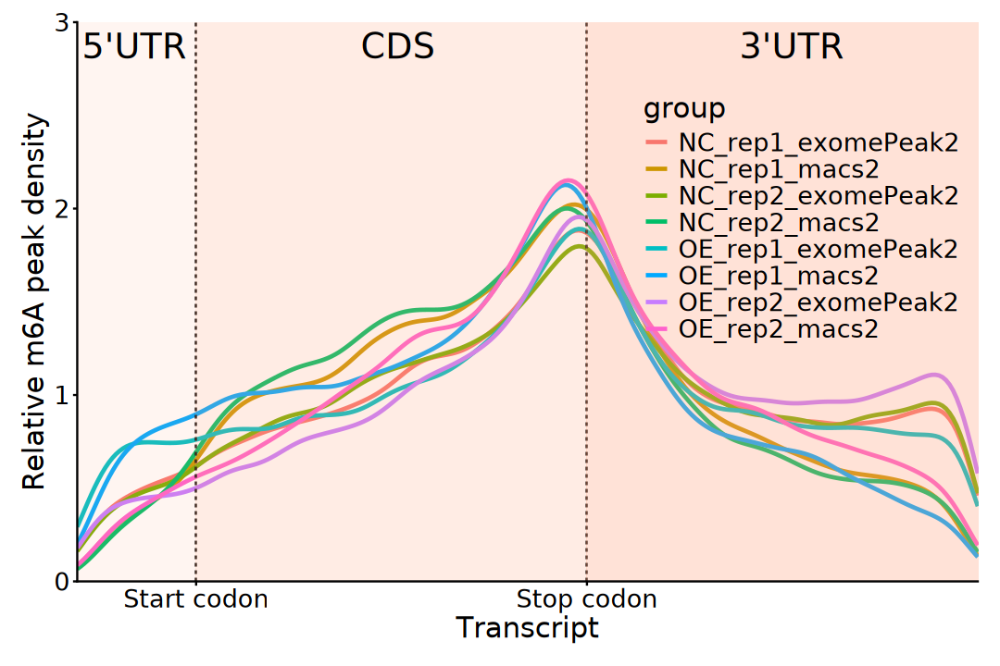

In [32]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot_guitar_dat$data |> 
    mutate(group = sub("HCCLM3_ALKBH5_", "", group)) |>
ggplot(aes(x = x, y = density, colour = group)) +
    geom_line(alpha = 1, linewidth = 1) +
    geom_vline(
        aes(xintercept = sum(txMrnaComponentProp[1:2])), linetype = "dashed") + 
    geom_vline(
        aes(xintercept = sum(txMrnaComponentProp[1:3])), linetype = "dashed") + 
    annotate(
        "rect", xmin = 0, xmax = sum(txMrnaComponentProp[1:2]), 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.1) +
    annotate(
        "rect", xmin = sum(txMrnaComponentProp[1:2]), 
        xmax = sum(txMrnaComponentProp[1:3]), 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.2) +
    annotate(
        "rect", xmin = sum(txMrnaComponentProp[1:3]), xmax = 1, 
        ymin = 0, ymax = 3, fill = "LightSalmon", alpha = 0.3) +
    annotate("text", x = 0.063, y = 3, label = "5'UTR", vjust = 1.4, size = 8) +
    annotate("text", x = 0.356, y = 3, label = "CDS", vjust = 1.4, size = 8) +
    annotate("text", x = 0.793, y = 3, label = "3'UTR", vjust = 1.4, size = 8) +
    scale_x_continuous(
        breaks = c(
            sum(txMrnaComponentProp[1:2]), 
            sum(txMrnaComponentProp[1:3])), 
        labels = c("Start codon", "Stop codon"), expand = c(0, 0)) +
    scale_y_continuous(expand = c(0, 0)) +
    labs(x = "Transcript", y = "Relative m6A peak density") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        panel.spacing.x = unit(0, "lines"), 
        strip.placement = "outside", 
        strip.background = element_blank(), 
        strip.text.x = element_text(size = 16, margin = margin(t = 4)),
        legend.position = "inside",
        legend.position.inside = c(0.80, 0.65),
        legend.background = element_blank(),
        legend.key = element_rect(fill = NA),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 6). Peak Metagene

In [34]:
suppressPackageStartupMessages(library(EnrichedHeatmap))

In [35]:
# Build representative protein-coding transcript model
tx_info <- transcriptLengths(
    txdb, with.cds_len = TRUE, with.utr5_len = TRUE, with.utr3_len = TRUE) |>
    as.data.frame() |>
    left_join(
        gtf |> as.data.frame() |> 
        dplyr::select(transcript_id, gene_type) |>
        distinct(), by = c("tx_name" = "transcript_id")) |>
    filter(
        gene_type == "protein_coding",
        utr5_len >= 50, cds_len >= 100, utr3_len >= 100) |>
    group_by(gene_id) |>
    filter(utr5_len >= 50, utr3_len >= 100, cds_len >= 100) |>
    ungroup()

head(tx_info)

tx_id,tx_name,gene_id,nexon,tx_len,cds_len,utr5_len,utr3_len,gene_type
<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<chr>
40,ENST00000641515.2,ENSG00000186092.7,3,2618,978,60,1580,protein_coding
318,ENST00000616016.5,ENSG00000187634.13,14,3465,2532,509,424,protein_coding
319,ENST00000618323.5,ENSG00000187634.13,14,3468,2535,509,424,protein_coding
321,ENST00000342066.8,ENSG00000187634.13,14,2557,2043,90,424,protein_coding
333,ENST00000338591.8,ENSG00000187961.15,12,2567,1926,110,531,protein_coding
337,ENST00000379410.8,ENSG00000187583.11,16,3176,1833,50,1293,protein_coding


In [36]:
# Get all exons of representative transcripts
exons_by_tx <- exonsBy(txdb, by = "tx", use.names = TRUE)
exons_by_tx <- exons_by_tx[tx_info$tx_name]

# Keep transcript information in exactly the same order
tx_info <- tx_info |>
    filter(tx_name %in% names(exons_by_tx)) |>
    arrange(match(tx_name, names(exons_by_tx)))

exons_by_tx <- exons_by_tx[tx_info$tx_name]

In [37]:
# Build genomic-to-transcript exon map
map_peaks_to_transcripts <- function(
    peaks, exons_by_tx, tx_info, ignore_strand = FALSE) {

    # Use peak centers to represent m6A peak positions
    peak_center <- resize(peaks, width = 1, fix = "center")
    peak_center$peak_id <- seq_along(peak_center)

    # Map genomic coordinates to spliced transcript coordinates
    mapped <- mapToTranscripts(
        peak_center, exons_by_tx, ignore.strand = ignore_strand)

    mapped_df <- as.data.frame(mapped) |>
        transmute(
            transcript_id = as.character(seqnames), tx_position = start,
            peak_id = mcols(mapped)$xHits) |>
        left_join(
            tx_info |>
                dplyr::select(
                    transcript_id = tx_name, gene_id, 
                    utr5_len, cds_len, utr3_len),
            by = "transcript_id")
    
    mapped_df
}

In [38]:
# Assign mapped peaks to transcript regions
assign_transcript_region <- function(mapped_df) {
    mapped_df |> 
        mutate(
            region = case_when(
                tx_position <= utr5_len ~ "5UTR",
                tx_position <= utr5_len + cds_len ~ "CDS",
                tx_position <= utr5_len + cds_len + utr3_len ~ "3UTR",
                TRUE ~ NA_character_
            ),
            region_position = case_when(
                region == "5UTR" ~ tx_position,
                region == "CDS" ~ tx_position - utr5_len,
                region == "3UTR" ~ tx_position - utr5_len - cds_len
            ),
            region_length = case_when(
                region == "5UTR" ~ utr5_len,
                region == "CDS" ~ cds_len,
                region == "3UTR" ~ utr3_len
            )) |>
        filter(!is.na(region))
}

In [39]:
# Normalize transcript positions into metagene bins
assign_metagene_bins <- function(
    mapped_df, bins = c("5UTR" = 10, "CDS" = 20, "3UTR" = 20)) {
    mapped_df |>
        mutate(
            n_bin = bins[region],
            bin = pmin(ceiling(region_position / region_length * n_bin), n_bin),
            metagene_bin = case_when(
                region == "5UTR" ~ bin,
                region == "CDS" ~ bins["5UTR"] + bin,
                region == "3UTR" ~ bins["5UTR"] + bins["CDS"] + bin
            )
        )
}

In [40]:
# Construct transcript-by-bin matrix

make_metagene_matrix <- function(
    peaks, exons_by_tx, tx_info, bins = c("5UTR" = 10, "CDS" = 20, "3UTR" = 20), 
    ignore_strand = FALSE) {

    mapped_df <- map_peaks_to_transcripts(
        peaks, exons_by_tx, tx_info, ignore_strand = ignore_strand) |>
        assign_transcript_region() |>
        assign_metagene_bins(bins = bins)

    n_bins <- sum(bins)

    mat <- matrix(
        0, nrow = nrow(tx_info), ncol = n_bins,
        dimnames = list(tx_info$tx_name, seq_len(n_bins))
    )

    peak_count <- mapped_df |>
        count(transcript_id, metagene_bin, name = "n")

    row_idx <- match(peak_count$transcript_id, rownames(mat))

    mat[cbind(row_idx, peak_count$metagene_bin)] <- peak_count$n

    colnames(mat) <- c(
        paste0("5UTR_", seq_len(bins["5UTR"])),
        paste0("CDS_", seq_len(bins["CDS"])),
        paste0("3UTR_", seq_len(bins["3UTR"]))
    )

    mat
}

In [41]:
metagene_mat_list <- lapply(
    peaks_list, make_metagene_matrix, 
    exons_by_tx = exons_by_tx, tx_info = tx_info
)

In [42]:
sample_order <- coldata |>
    rownames_to_column("sample") |>
    arrange(Method, Genotype, Replicate) |>
    pull(sample)

metagene_mat_list <- metagene_mat_list[sample_order]

In [43]:
# Calculate mean peak density across transcripts
profile_df <- map_dfr(
    metagene_mat_list, ~ data.frame(
        bin = seq_len(ncol(.x)),
        density = colMeans(.x)
    ), .id = "sample"
) |>
    left_join(coldata |> rownames_to_column("sample"), by = "sample")

head(profile_df)

,sample,bin,density,Cell,Genotype,Replicate,Method
,<chr>,<int>,<dbl>,<chr>,<fct>,<fct>,<fct>
1,HCCLM3_ALKBH5_NC_rep1_macs2,1,0.0004135991,HCCLM3,ALKBH5-NC,rep1,macs2
2,HCCLM3_ALKBH5_NC_rep1_macs2,2,0.0008437422,HCCLM3,ALKBH5-NC,rep1,macs2
3,HCCLM3_ALKBH5_NC_rep1_macs2,3,0.0014724129,HCCLM3,ALKBH5-NC,rep1,macs2
4,HCCLM3_ALKBH5_NC_rep1_macs2,4,0.0019191000,HCCLM3,ALKBH5-NC,rep1,macs2
5,HCCLM3_ALKBH5_NC_rep1_macs2,5,0.0024650509,HCCLM3,ALKBH5-NC,rep1,macs2
6,HCCLM3_ALKBH5_NC_rep1_macs2,6,0.0025146828,HCCLM3,ALKBH5-NC,rep1,macs2


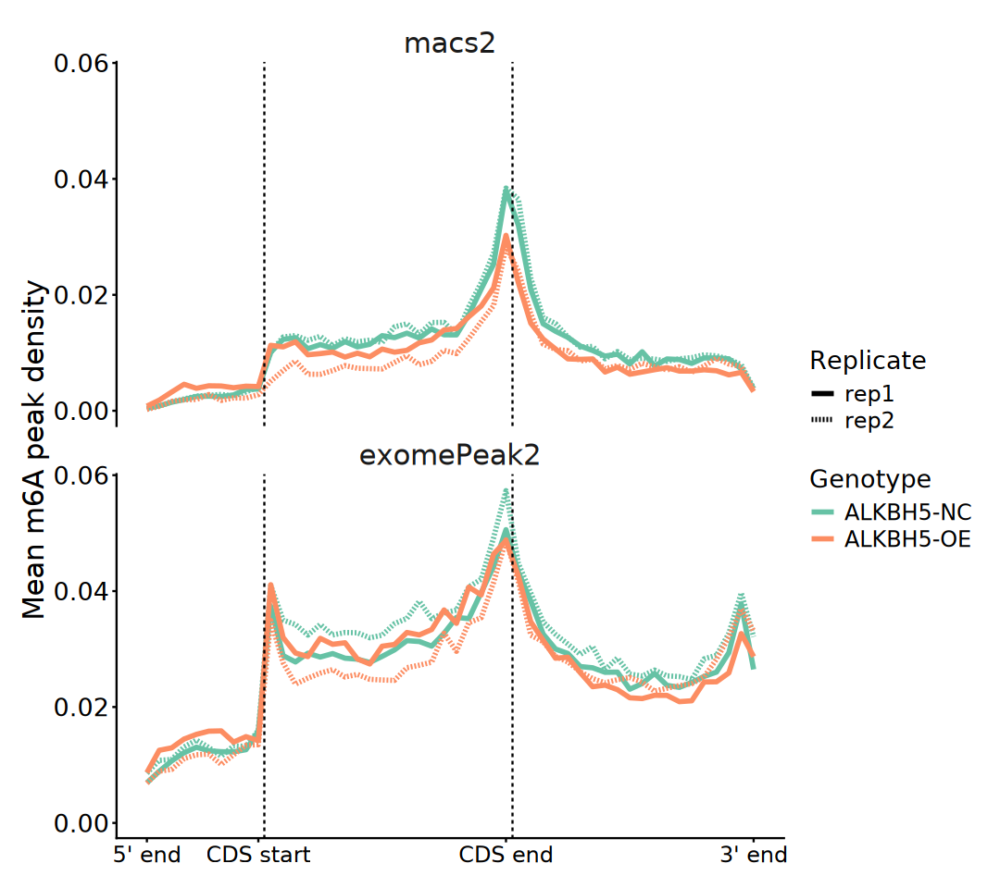

In [44]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(profile_df, aes(bin, density, group = sample)) +
    geom_line(aes(color = Genotype, linetype = Replicate), linewidth = 1.2) +
    geom_vline(xintercept = c(10.5, 30.5), linetype = "dashed") +
    scale_x_continuous(
        breaks = c(1, 10, 30, 50),
        labels = c("5' end", "CDS start", "CDS end", "3' end")) +
    scale_color_brewer(palette = "Set2") +
    facet_wrap(~ Method, nrow = 2) +
    labs(
        x = NULL, y = "Mean m6A peak density", 
        color = "Genotype", linetype = "Replicate") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        # panel.spacing.x = unit(0, "lines"),
        strip.background = element_blank(),
        strip.text = element_text(size = 18),
        legend.title = element_text(size = 16),
        legend.text = element_text(size = 14),
        axis.title = element_text(size = 18),
        axis.text.x = element_text(size = 14),
        axis.text.y = element_text(size = 16))

In [45]:
metagene_norm_list <- lapply(metagene_mat_list, function(mat) {
    as.normalizedMatrix(
        mat, 
        k_upstream = 10,
        k_target = 20,
        k_downstream = 20,
        extend = c(1, 1),
        signal_name = "m6A peak",
        target_name = "CDS"
    )
})

In [46]:
mean_signal <- Reduce("+", lapply(metagene_mat_list, rowSums)) / 
    length(metagene_mat_list)

row_order <- order(mean_signal, decreasing = TRUE)

In [47]:
unified_cols <- circlize::colorRamp2(c(0, 1), c("white", "#08519C"))

signal_lgd <- Legend(col_fun = unified_cols, title = "FPKM")

In [48]:
ht_list <- lapply(seq_along(metagene_norm_list), function(i) {
    sample <- sub("HCCLM3_ALKBH5_", "", names(metagene_norm_list)[i])

    EnrichedHeatmap(
        metagene_norm_list[[i]],
        name = sample,
        column_title = sample,
        col = unified_cols,
        row_order = row_order,
        cluster_rows = FALSE,
        show_row_names = FALSE,
        show_heatmap_legend = FALSE,
        axis_name = c("5' end", "CDS-S", "CDS-E", "3' end"), 
        top_annotation = HeatmapAnnotation(
            enriched = anno_enriched(
                gp = gpar(lwd = 2, col = "#df0d0d"), 
                axis_param = list(gp = gpar(fontsize = 10))), 
            height = unit(3, "cm"), 
            show_legend = FALSE), 
        use_raster = TRUE)
})

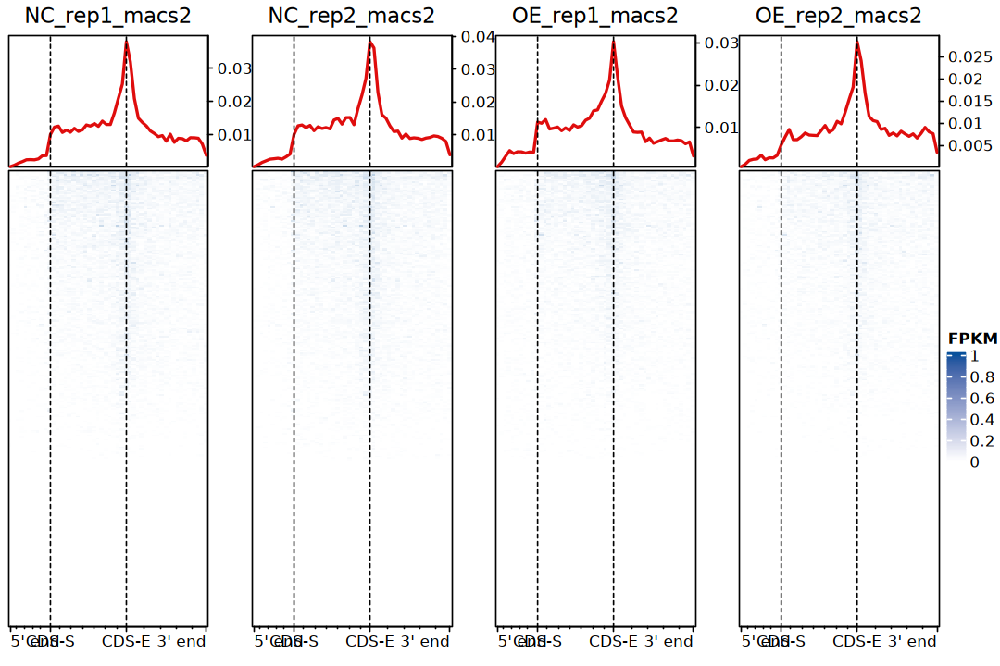

In [49]:
options(repr.plot.width = 9, repr.plot.height = 6)

draw(
    Reduce(`+`, ht_list[1:4]), 
    heatmap_legend_side = "right", 
    annotation_legend_list = list(signal_lgd),
    ht_gap = unit(10, "mm")
)

# 4. Transcriptome-wide Landscape

In [34]:
suppressPackageStartupMessages(library(DESeq2))

In [55]:
raw_counts <- file.path(data_dir, "08_counts", "featureCounts.all.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

dim(raw_counts)

[1] 78686    16

In [56]:
coldata <- data.frame(sample = colnames(raw_counts)) |>
    filter(str_detect(sample, fixed("HCCLM3"))) |>
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate", "Assay"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE
    ) |>
    mutate( 
        Group = factor(Group, levels = c("NC", "OE")), 
        Genotype = forcats::fct_cross(Gene, Group, sep = "_"), 
        Replicate = factor(Replicate), 
        Assay = factor(Assay, levels = c("m6A", "Input"))
    ) |>
    arrange(Cell, Genotype, Replicate) |>
    column_to_rownames("sample")

In [57]:
anno_gene <- raw_counts |>
    dplyr::select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |>
    DataFrame()

In [58]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    dplyr::select(any_of(rownames(coldata))) |>
    as.matrix()

In [59]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene, 
    colData = coldata, design = ~ Genotype)
dds

class: DESeqDataSet 
dim: 78686 8 
metadata(1): version
assays(1): counts
rownames(78686): ENSG00000290825.2 ENSG00000223972.6 ...
  ENSG00000210195.2 ENSG00000210196.2
rowData names(3): symbol type basepairs
colnames(8): HCCLM3_ALKBH5_NC_rep1_Input HCCLM3_ALKBH5_NC_rep1_m6A ...
  HCCLM3_ALKBH5_OE_rep2_Input HCCLM3_ALKBH5_OE_rep2_m6A
colData names(6): Cell Gene ... Assay Genotype

In [60]:
keep <- rowSums(counts(dds) >= 10) >= 3

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dds <- dds[keep, ]

Filtered genes summary:
 Pass: 17485 
 Remove: 61201 
 Retention rate: 22.22 %


In [61]:
rld <- rlog(dds, blind = FALSE)

## 1). PCA

In [62]:
pca_res <- plotPCA(
    rld, intgroup = c("Genotype", "Assay"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



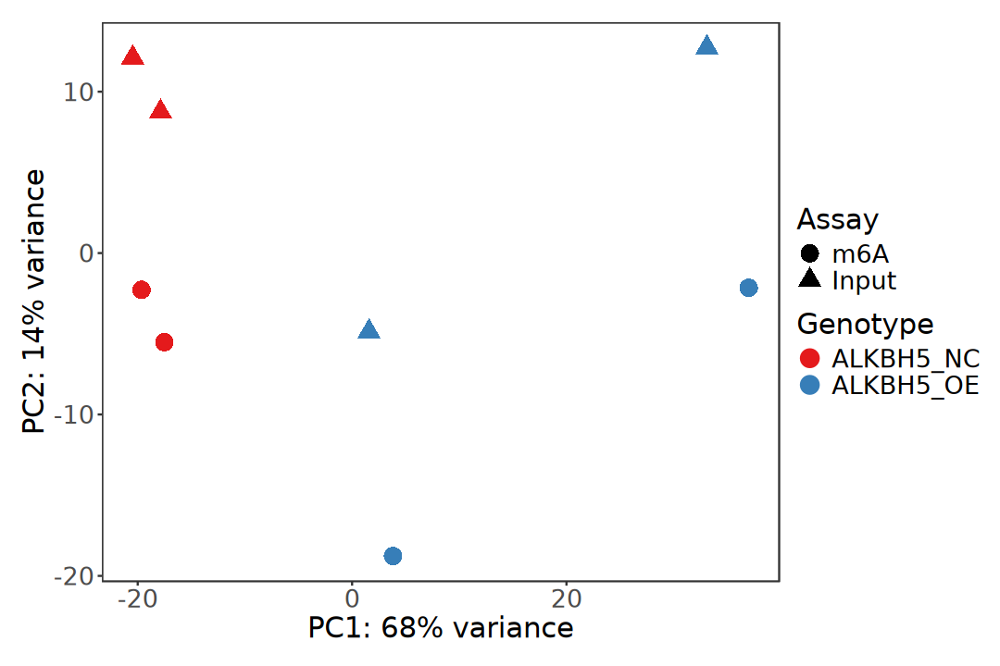

In [63]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Genotype, shape = Assay), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). Heatmap

In [64]:
pca_genes <- assay(rld) |>
    matrixStats::rowVars() |>
    setNames(rownames(rld)) |>
    sort(decreasing = TRUE) |>
    head(2000) |>
    names()

In [65]:
ac <- colData(dds) |>
    as.data.frame() |>
    dplyr::select(Replicate, Group)

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

anno_colors <- list(Group = group_colors, Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

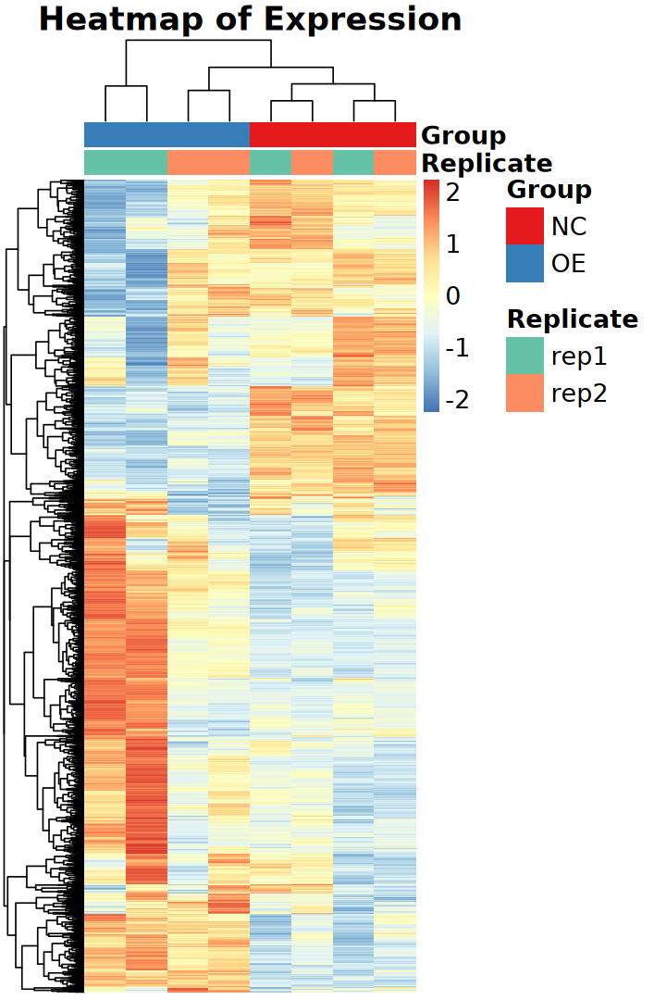

In [66]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    assay(rld)[pca_genes, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. Differential m6A Peak

In [33]:
output_dir <- file.path(data_dir, "09_DifferentialPeak")
dir.create(output_dir, recursive = TRUE, showWarnings = FALSE)

## 1). DESeq2

In [81]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

### a). Genes

In [82]:
dds

class: DESeqDataSet 
dim: 17485 8 
metadata(1): version
assays(4): counts mu H cooks
rownames(17485): ENSG00000310526.1 ENSG00000310527.1 ...
  ENSG00000210195.2 ENSG00000210196.2
rowData names(33): symbol type ... deviance maxCooks
colnames(8): HCCLM3_ALKBH5_NC_rep1_Input HCCLM3_ALKBH5_NC_rep1_m6A ...
  HCCLM3_ALKBH5_OE_rep2_Input HCCLM3_ALKBH5_OE_rep2_m6A
colData names(7): Cell Gene ... Genotype sizeFactor

In [ ]:
dds$bio_id <- paste(dds$Genotype, dds$Replicate, sep = "_") |>
    factor()
dds$ip <- as.integer(dds$Assay == "IP")
dds$ko_ip <- dds$ip * as.integer(dds$Genotype == "KO")

In [89]:
# design(dds) <- ~ Genotype * Assay
design(dds) <- ~ Genotype + Genotype:Replicate + Genotype:Assay

In [90]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

found already estimated dispersions, replacing these

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [91]:
resultsNames(dds)

[1] "Intercept"                       "Genotype_ALKBH5_OE_vs_ALKBH5_NC"
[3] "GenotypeALKBH5_NC.Replicaterep2" "GenotypeALKBH5_OE.Replicaterep2"
[5] "GenotypeALKBH5_NC.AssayInput"    "GenotypeALKBH5_OE.AssayInput"

In [92]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 17485 with nonzero total read count
adjusted p-value < 0.05
LFC > 1.00 (up)    : 28, 0.16%
LFC < -1.00 (down) : 9, 0.051%
outliers [1]       : 0, 0%
low counts [2]     : 2034, 12%
(mean count < 14)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [105]:
deseq2_result <- res |> 
    as.data.frame() |>
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up", 
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down", 
            TRUE ~ "NS"
        ) |>
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |>
            as.data.frame() |>
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), by = "gene_id"
    ) |>
    arrange(padj, abs(logFC)) |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
deseq2_result |>
    dplyr::filter(type == "protein_coding") |>
    dplyr::select(symbol, logFC, pvalue, padj, result) |>
    head()


   Up  Down    NS 
   28     9 17448 

,symbol,logFC,pvalue,padj,result
,<chr>,<dbl>,<dbl>,<dbl>,<fct>
ENSG00000117450.15,PRDX1,1.559190,6.632294e-11,5.123779e-07,Up
ENSG00000121073.15,SLC35B1,1.696121,2.784250e-09,1.433982e-05,Up
ENSG00000165672.7,PRDX3,1.657415,2.366408e-08,7.312673e-05,Up
ENSG00000167553.17,TUBA1C,1.548831,3.436852e-08,8.850466e-05,Up
ENSG00000008282.10,SYPL1,1.595575,6.775553e-08,1.495558e-04,Up
ENSG00000114544.17,SLC41A3,1.740608,1.092262e-07,2.109568e-04,Up


### b). Peaks

## 2). exomePeak2

In [19]:
suppressPackageStartupMessages(library(exomePeak2))

In [20]:
bam_files <- file.path(data_dir, "04_bam") |>
    list.files(pattern = "\\.bam$", full.names = TRUE) |>
    rlang::set_names(~ sub("(.*)\\.bam$", "\\1", basename(.x)))

paste(names(bam_files), basename(bam_files), sep = ": ") |> 
    cat(sep = "\n")

HCCLM3_ALKBH5_NC_rep1_Input: HCCLM3_ALKBH5_NC_rep1_Input.bam
HCCLM3_ALKBH5_NC_rep1_m6A: HCCLM3_ALKBH5_NC_rep1_m6A.bam
HCCLM3_ALKBH5_NC_rep2_Input: HCCLM3_ALKBH5_NC_rep2_Input.bam
HCCLM3_ALKBH5_NC_rep2_m6A: HCCLM3_ALKBH5_NC_rep2_m6A.bam
HCCLM3_ALKBH5_OE_rep1_Input: HCCLM3_ALKBH5_OE_rep1_Input.bam
HCCLM3_ALKBH5_OE_rep1_m6A: HCCLM3_ALKBH5_OE_rep1_m6A.bam
HCCLM3_ALKBH5_OE_rep2_Input: HCCLM3_ALKBH5_OE_rep2_Input.bam
HCCLM3_ALKBH5_OE_rep2_m6A: HCCLM3_ALKBH5_OE_rep2_m6A.bam


In [21]:
CTRL_IP_BAM <- bam_files[c(2, 4)]
CTRL_INPUT_BAM <- bam_files[c(1, 3)]
TREAT_IP_BAM <- bam_files[c(6, 8)]
TREAT_INPUT_BAM <- bam_files[c(5, 7)]

In [ ]:
Poisson

In [ ]:
# Differential m6A Peaks Analysis
# ~ 120 min (1 core)
exomepeak2_dmp <- exomePeak2(
    bam_ip = CTRL_IP_BAM, 
    bam_input = CTRL_INPUT_BAM, 
    bam_ip_treated = TREAT_IP_BAM, 
    bam_input_treated = TREAT_INPUT_BAM, 
    txdb = txdb, 
    genome = "hg38", 
    strandness = "unstrand", 
    fragment_length = 100, 
    bin_size = 25, 
    step_size = 25, 
    test_method = "DESeq2", 
    p_cutoff = 1e-5, 
    diff_p_cutoff = 0.05, 
    parallel = 1, 
    save_dir = file.path(output_dir, "exomePeak2"), 
    experiment_name = "ALKBH5_OE-NC"
)

Extract bin features ... 
OK

Count reads on bin features ... 


In [45]:
exomepeak2_dmp

GRangesList object of length 0:
<0 elements>

## 3). [TRESS](https://github.com/ZhenxingGuo0015/TRESS)

> 1. Divide the whole genome to obtain bin-level read counts.
> 2. Call candidate differential m6A methylation regions (DMRs).
> 3. Model fitting on candidate DMRs based on Negative Binomial distribution.

In [22]:
suppressPackageStartupMessages(library(TRESS))

In [23]:
txdb_sqlite <- file.path("~/reference/Homo_sapiens/hg38", "gencode.v48.sqlite")
AnnotationDbi::saveDb(txdb, file = txdb_sqlite)

TxDb object:
# Db type: TxDb
# Supporting package: GenomicFeatures
# Genome: hg38
# Gencode Release: v48
# Organism: Homo sapiens
# Taxonomy ID: 9606
# Nb of transcripts: 385632
# Db created by: txdbmaker package from Bioconductor
# Creation time: 2026-09-18 15:49:00 +0800 (Fri, 18 Sep 2026)
# txdbmaker version at creation time: 1.6.2
# RSQLite version at creation time: 3.53.3
# DBSCHEMAVERSION: 1.2

In [26]:
IP_BAM <- bam_files[c(2, 4, 6, 8)] |> basename()
INPUT_BAM <- bam_files[c(1, 3, 5, 7)] |> basename()

In [ ]:
dir.create(
    file.path(output_dir, "TRESS"), 
    recursive = TRUE, showWarnings = FALSE
)

In [32]:
# ~ 60 min
DMR.fit = TRESS_DMRfit(
    IP.file = IP_BAM, 
    Input.file = INPUT_BAM, 
    Path_To_AnnoSqlite = txdb_sqlite, 
    variable = coldata, 
    model = ~ 1 + Genotype, 
    InputDir = file.path(data_dir, "04_bam"), 
    OutputDir = file.path(output_dir, "TRESS"), 
    experimentName = "ALKBH5_OE-NC", 
    binsize = 50, 
    WhichThreshold = "fdr", 
    pval.cutoff = 1e-05, 
    fdr.cutoff = 0.05, 
    lfc.cutoff = 0.4,
    IncludeIntron = TRUE, 
    filetype = "bam", 
    filterRegion = TRUE, 
    shrkPhi = TRUE, 
    addsuedo = FALSE
)

##### Divid the genome into bins and obtain bin counts...
Time used to obtain bin-level data is: 
18.1479
##### Step 1: Call candidate DMRs...
Merge bumps from different replicates...
The number of candidates is: 
39101
Time used in Step 1 is: 
28.5495
##### Step 2: Model fitting on candidates...
[1] "Start to estimate preliminary MLE ..."


Warning message in mclapply(seq_len(nrow(Ratio)), iMLE, X, Y, sx, sy, Ratio, D, :
"all scheduled cores encountered errors in user code"


ERROR: Error in (function (cond) : error in evaluating the argument 'x' in selecting a method for function 'as.matrix': subscript out of bounds


In [ ]:
CoefName(DMR.fit)

In [ ]:
CoefName(DMR.fit)
Contrast = "YourContrast" # e.g., Contrast = c(0, 1)

DMR.test <- TRESS_DMRtest(DMR = DMR.fit, contrast = Contrast)

# *Reference